# **02 - Training Model**

**Alur:** setup -> fungsi inti (cache, dataset, model, evaluasi) -> konfigurasi -> DataLoader -> model -> training -> kurva -> interpretasi. Keluaran: `best.pt` (bobot terbaik), `history.csv`, dan cache gambar di `/kaggle/working`.

1. **Setup dan lokasi data**

Mengimpor library dasar, menetapkan nama kompetisi, lalu mencari folder dataset di Kaggle. Data kompetisi ter-*mount* di `/kaggle/input/competitions/<slug>` (kode juga mencoba lokasi alternatif). Variabel `WORK` adalah folder keluaran (`/kaggle/working`), `CLASS_NAMES` adalah 16 kelas sesuai urutan `label` 0-15, dan `SEED` dipakai agar hasil bisa diulang.

**Hasil:** `DATA_DIR` terdeteksi di `/kaggle/input/competitions/document-image-classification-sd234504`.

In [ ]:
import os, time, random, warnings, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

COMP = "document-image-classification-sd234504"
CANDIDATES = [Path(f"/kaggle/input/{COMP}"), Path(f"/kaggle/input/competitions/{COMP}")]
DATA_DIR = next((p for p in CANDIDATES if (p / "train.csv").exists()), None)
if DATA_DIR is None:
    hits = [h for pat in ("*/train.csv", "*/*/train.csv", "*/*/*/train.csv") for h in glob.glob("/kaggle/input/" + pat)]
    assert hits, "Dataset kompetisi belum ditambahkan! Klik 'Add Input' -> tab Competition."
    DATA_DIR = Path(hits[0]).parent
WORK = Path("/kaggle/working")
CLASS_NAMES = ["advertisement", "budget", "email", "file_folder", "form", "handwritten",
               "invoice", "letter", "memo", "news_article", "presentation", "questionnaire",
               "resume", "scientific_publication", "scientific_report", "specification"]
SEED = 42
print("DATA_DIR:", DATA_DIR)

DATA_DIR: /kaggle/input/competitions/document-image-classification-sd234504


2. **Fungsi inti**

Blok-blok kode berikut berisi fungsi inti (cache, dataset, model, evaluasi) yang dipakai sepanjang notebook.

2.1. **Impor, konstanta, dan device**

Mengimpor PyTorch dan utilitas pendukung, lalu menetapkan konstanta: jumlah kelas (16), ukuran input 224x224 piksel (sesuai DiT), nama backbone `microsoft/dit-base`, ukuran batch 32, porsi validasi 10%, jumlah worker DataLoader 2, dan `DEVICE` (GPU jika ada, selain itu CPU).

In [ ]:
import torch, torch.nn.functional as F
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, Subset

NUM_CLASSES = len(CLASS_NAMES)
SIZE = 224
MODEL_NAME = "microsoft/dit-base"
BATCH_SIZE, VAL_FRACTION, NUM_WORKERS = 32, 0.1, 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

2.2. **Fungsi `seed_everything`**

Mengunci seed Python, NumPy, dan PyTorch agar pembagian data dan inisialisasi head model sama setiap kali dijalankan (*reproducible*).

In [ ]:
def seed_everything(seed):
    """Set seed Python, NumPy, dan PyTorch agar hasil reproducible."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

2.3. **Fungsi membaca gambar: `resolve_path`, `load_image`, `prep_image`**

- `resolve_path`: mencari lokasi file gambar karena path di CSV (`train/...`) bisa berbeda dari struktur folder di disk.
- `load_image`: membuka TIFF dengan beberapa decoder cadangan (Pillow, lalu tifffile). Jika file korup/terpotong, diganti halaman putih agar proses tidak berhenti.
- `prep_image`: mengubah satu gambar menjadi grayscale 224x224 (array uint8) yang siap disimpan di cache.

In [ ]:
def resolve_path(root, filename):
    """Mencari lokasi file gambar di disk.

    CSV menulis ``train/invoice/x.tif`` sedangkan di disk bisa ``train/train/invoice/x.tif``.

    Args:
        root: Folder dataset.
        filename: Kolom ``filename`` dari CSV.

    Returns:
        Path file yang ditemukan.
    """
    root = Path(root)
    for p in (root / filename, root / filename.split("/")[0] / filename):
        if p.exists():
            return p
    raise FileNotFoundError(f"{filename} tidak ditemukan di {root}")


def load_image(path):
    """Membuka gambar dengan fallback decoder; file korup diganti halaman putih.

    Args:
        path: Lokasi file gambar.

    Returns:
        Citra PIL mode RGB.
    """
    try:
        return Image.open(path).convert("RGB")
    except Exception:
        pass
    try:
        import tifffile
        return Image.fromarray(tifffile.imread(str(path))).convert("RGB")
    except Exception:
        pass
    warnings.warn(f"Gambar tidak terbaca, diganti halaman putih: {path}")
    return Image.new("RGB", (224, 224), (255, 255, 255))


def prep_image(path, size=SIZE):
    """Decode satu gambar -> grayscale uint8 ``size`` x ``size``."""
    img = load_image(path).convert("L").resize((size, size), Image.BILINEAR)
    return np.asarray(img, dtype=np.uint8)

2.4. **Fungsi cache gambar: `find_existing` dan `build_cache`**

- `find_existing`: mencari file hasil run sebelumnya (mis. cache atau `best.pt`) di `/kaggle/working` atau di input notebook lain.
- `build_cache`: men-decode semua gambar sekali (paralel dengan beberapa thread) dan menyimpannya sebagai satu array `.npy`. Epoch berikutnya cukup membaca array ini, sehingga jauh lebih cepat daripada membuka TIFF berulang kali. Jika cache sudah ada, langsung dipakai ulang.

In [ ]:
def find_existing(name):
    """Mencari file hasil run sebelumnya (di /kaggle/working atau di input notebook lain).

    Returns:
        Path file jika ada, selain itu None.
    """
    for pattern in (str(WORK / name), f"/kaggle/input/*/{name}", f"/kaggle/input/*/*/{name}", f"/kaggle/input/*/*/*/{name}"):
        hits = glob.glob(pattern)
        if hits:
            return Path(hits[0])
    return None


def build_cache(df, name, workers=4):
    """Membuat (atau memakai ulang) cache array gambar uint8 (N, 224, 224).

    Args:
        df: DataFrame dengan kolom ``filename``.
        name: Nama file cache ``.npy``.
        workers: Jumlah thread decoding.

    Returns:
        Path file cache.
    """
    found = find_existing(name)
    if found is not None:
        print("Memakai cache:", found)
        return found
    path = WORK / name
    paths = [resolve_path(DATA_DIR, f) for f in df["filename"]]
    arr = np.lib.format.open_memmap(path, mode="w+", dtype=np.uint8, shape=(len(paths), SIZE, SIZE))
    with ThreadPoolExecutor(workers) as ex:
        for i, a in enumerate(tqdm(ex.map(prep_image, paths), total=len(paths), desc=name)):
            arr[i] = a
    arr.flush()
    return path

2.5. **Kelas `CachedDataset`**

Dataset PyTorch yang membaca gambar dari cache. Setiap gambar dinormalisasi (mean 0,5, std 0,5) dan diulang ke 3 channel sesuai input DiT. Pada mode `train=True`, ditambahkan augmentasi geser acak kecil (hingga 8 piksel) untuk meniru pergeseran pada dokumen hasil pindai.

In [ ]:
class CachedDataset(Dataset):
    """Dataset dari cache: normalisasi (mean 0.5, std 0.5), 3 channel, augmentasi geser ringan.

    Args:
        cache_path: File ``.npy`` hasil ``build_cache``.
        labels: Array label (None untuk test).
        train: Jika True, aktifkan augmentasi geser acak kecil.
    """

    def __init__(self, cache_path, labels=None, train=False):
        """Memuat cache (memory-mapped) dan menyimpan label."""
        self.arr = np.load(cache_path, mmap_mode="r")
        self.labels, self.train = labels, train

    def __len__(self):
        """Jumlah sampel."""
        return len(self.arr)

    def __getitem__(self, i):
        """Mengambil satu sampel: ``(tensor, label)`` atau hanya tensor bila tanpa label."""
        x = torch.from_numpy(np.array(self.arr[i])).float().div_(255.0)
        if self.train:
            dx, dy = np.random.randint(-8, 9, size=2)
            x = torch.roll(x, shifts=(int(dy), int(dx)), dims=(0, 1))
        x = ((x - 0.5) / 0.5).unsqueeze(0).expand(3, -1, -1).contiguous()
        return x if self.labels is None else (x, torch.tensor(int(self.labels[i])))

2.6. **Fungsi DataLoader: `build_loaders` dan `build_test_loader`**
- `build_loaders`: membuat cache train, membagi data menjadi train dan validasi dengan *stratified split* (proporsi kelas terjaga, seed tetap), lalu membungkusnya menjadi DataLoader.
- `build_test_loader`: membuat cache test dan DataLoader untuk prediksi akhir (tanpa label).

In [ ]:
def build_loaders():
    """Membuat DataLoader train & validasi (stratified split) dari train.csv.

    Returns:
        Tuple ``(train_loader, val_loader, train_df)``.
    """
    df = pd.read_csv(DATA_DIR / "train.csv")
    cache = build_cache(df, f"cache_train_{SIZE}.npy")
    tr_i, va_i = train_test_split(np.arange(len(df)), test_size=VAL_FRACTION,
                                  stratify=df["label"], random_state=SEED)
    y = df["label"].values
    train = Subset(CachedDataset(cache, y, train=True), tr_i)
    val = Subset(CachedDataset(cache, y), va_i)
    kw = dict(num_workers=NUM_WORKERS, pin_memory=True)
    return (DataLoader(train, BATCH_SIZE, shuffle=True, drop_last=True, **kw),
            DataLoader(val, BATCH_SIZE * 2, **kw), df)


def build_test_loader():
    """Membuat DataLoader untuk test.csv.

    Returns:
        Tuple ``(test_loader, test_df)``.
    """
    df = pd.read_csv(DATA_DIR / "test.csv")
    cache = build_cache(df, f"cache_test_{SIZE}.npy")
    return DataLoader(CachedDataset(cache), BATCH_SIZE * 2, num_workers=NUM_WORKERS, pin_memory=True), df

2.7. **Fungsi `build_model`**

Memuat backbone Transformer `microsoft/dit-base` (pre-trained pada dokumen) dan mengganti head klasifikasi menjadi 16 kelas kompetisi. Bobot head baru diinisialisasi acak, sedangkan bobot backbone dipertahankan lalu di-*fine-tune*.

In [ ]:
def build_model(name=MODEL_NAME):
    """Membuat model Transformer pre-trained dengan head baru 16 kelas.

    Args:
        name: Nama model di HuggingFace Hub.

    Returns:
        Model PyTorch (keluaran logits (B, 16)).
    """
    from transformers import AutoModelForImageClassification
    return AutoModelForImageClassification.from_pretrained(
        name, num_labels=NUM_CLASSES, id2label=dict(enumerate(CLASS_NAMES)),
        label2id={c: i for i, c in enumerate(CLASS_NAMES)}, ignore_mismatched_sizes=True)

2.8. **Fungsi `evaluate`**

Menghitung loss dan akurasi model pada DataLoader berlabel (mode evaluasi, tanpa gradien, dengan mixed precision). Mengembalikan loss, akurasi, label sebenarnya, dan label prediksi, yang dipakai untuk laporan per kelas dan confusion matrix.

In [ ]:
@torch.no_grad()
def evaluate(model, loader):
    """Mengevaluasi model pada DataLoader berlabel.

    Returns:
        Tuple ``(loss, akurasi, y_true, y_pred)``.
    """
    model.eval()
    loss, ys, ps = 0.0, [], []
    for x, y in tqdm(loader, leave=False, desc="eval"):
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            logits = model(pixel_values=x.to(DEVICE)).logits.float().cpu()
        loss += F.cross_entropy(logits, y, reduction="sum").item()
        ys.append(y); ps.append(logits.argmax(-1))
    yt, yp = torch.cat(ys), torch.cat(ps)
    return loss / len(yt), (yt == yp).float().mean().item(), yt.numpy(), yp.numpy()

3. **Konfigurasi training**

Menetapkan hyperparameter: 3 epoch, learning rate puncak 3e-5, weight decay 0,05, dan *label smoothing* 0,1 (mengurangi overconfidence). `MAX_MINUTES` adalah batas waktu opsional (tidak dipakai di sini). Seed dikunci dan device dicetak.

**Hasil:** training berjalan di GPU (`cuda`, Tesla T4).

In [ ]:
EPOCHS, LR, WEIGHT_DECAY, LABEL_SMOOTHING = 3, 3e-5, 0.05, 0.1
MAX_MINUTES = None
seed_everything(SEED)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "(!! CPU: aktifkan GPU di Settings)")

Device: cuda Tesla T4


4. **Membuat DataLoader**

Membangun cache gambar train (decode 32.003 TIFF sekali), membagi data train/validasi, dan membuat DataLoader.

**Hasil:** terdapat 900 batch train dan 51 batch validasi (sekitar 28.800 gambar latih dan 3.201 gambar validasi). Peringatan *Corrupt EXIF* dan `tifffile ... invalid offset` kemungkinan berasal dari satu file TIFF yang terpotong (lihat EDA), yang otomatis diganti halaman putih oleh `load_image`.

In [ ]:
train_loader, val_loader, train_df = build_loaders()
print("Batch train/val:", len(train_loader), len(val_loader))

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
<tifffile.TiffPages @85476> invalid offset to first page 85476


Batch train/val: 900 51


5. **Membuat model**

Memuat DiT-base dari Hugging Face dan memasang head 16 kelas, lalu memindahkannya ke GPU dan menghitung parameter yang dilatih.

**Hasil:** 85.820.944 parameter dilatih (seluruh model di-*fine-tune*). *Load report* menunjukkan `lm_head`/`layernorm` pra-latih tidak dipakai (UNEXPECTED), sedangkan `classifier` dan `pooler` baru (MISSING, diinisialisasi acak). Ini wajar untuk fine-tuning. Peringatan *unauthenticated request* hanya soal token Hugging Face dan bisa diabaikan.

In [ ]:
model = build_model().to(DEVICE)
print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

[transformers] BeitForImageClassification LOAD REPORT from: microsoft/dit-base
Key                          | Status     | 
-----------------------------+------------+-
lm_head.bias                 | UNEXPECTED | 
layernorm.weight             | UNEXPECTED | 
layernorm.bias               | UNEXPECTED | 
lm_head.weight               | UNEXPECTED | 
beit.pooler.layernorm.bias   | MISSING    | 
beit.pooler.layernorm.weight | MISSING    | 
classifier.weight            | MISSING    | 
classifier.bias              | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable params: 85820944


6. **Training**

6.1. **Fungsi `train_one_epoch`**

Satu epoch training: untuk setiap batch, hitung prediksi dengan mixed precision, loss *cross-entropy* dengan label smoothing, backpropagation lewat `GradScaler`, lalu perbarui bobot dan learning rate. Mengembalikan rata-rata loss epoch.

In [ ]:
def train_one_epoch(model, loader, optimizer, scheduler, scaler):
    """Melatih model satu epoch (mixed precision).

    Returns:
        Rata-rata loss epoch.
    """
    model.train()
    total, n = 0.0, 0
    for x, y in tqdm(loader, leave=False, desc="train"):
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            logits = model(pixel_values=x).logits.float()
            loss = F.cross_entropy(logits, y, label_smoothing=LABEL_SMOOTHING)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); scheduler.step()
        total += loss.item() * len(y); n += len(y)
    return total / n

6.2. **Fungsi `fit`**

Loop training utama: memakai optimizer AdamW dan scheduler OneCycleLR (learning rate naik lalu turun), memanggil `train_one_epoch` dan `evaluate` tiap epoch, mencatat riwayat, dan **menyimpan bobot dengan akurasi validasi tertinggi** ke `best.pt`. Dapat berhenti lebih awal lewat `max_minutes`.

In [ ]:
def fit(model, train_loader, val_loader, epochs, lr, ckpt_path, max_minutes=None):
    """Melatih beberapa epoch, menyimpan bobot dengan val accuracy terbaik.

    Returns:
        Riwayat training (list of dict).
    """
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * len(train_loader), pct_start=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    history, best, t0 = [], 0.0, time.time()
    for ep in range(1, epochs + 1):
        tl = train_one_epoch(model, train_loader, opt, sched, scaler)
        vl, va, _, _ = evaluate(model, val_loader)
        history.append(dict(epoch=ep, train_loss=tl, val_loss=vl, val_acc=va))
        elapsed = (time.time() - t0) / 60
        print(f"epoch {ep}/{epochs} train_loss={tl:.4f} val_loss={vl:.4f} val_acc={va:.4f} | {elapsed:.1f} menit")
        if va > best:
            best = va; torch.save(model.state_dict(), ckpt_path)
        if max_minutes and elapsed > max_minutes:
            print("Batas waktu tercapai, berhenti."); break
    return history

6.3. **Menjalankan training**

Memanggil `fit` selama 3 epoch dan menyimpan riwayat ke `history.csv`.

| Epoch | Train loss | Val loss | Val acc | Waktu kumulatif |
|---|---|---|---|---|
| 1 | 1,5217 | 0,6266 | 82,85% | 4,5 menit |
| 2 | 1,0107 | 0,5139 | 86,35% | 9,2 menit |
| 3 | 0,9284 | 0,4995 | 86,38% | 13,9 menit |

Pesan *lr_scheduler.step() before optimizer.step()* dan *Exception ignored in DataLoader* adalah peringatan rutin dari mixed precision dan penutupan worker, tidak memengaruhi hasil.

In [ ]:
history = fit(model, train_loader, val_loader, EPOCHS, LR, WORK / "best.pt", MAX_MINUTES)
hist = pd.DataFrame(history); hist.to_csv(WORK / "history.csv", index=False); hist

/tmp/ipykernel_50/3457253571.py:15: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); scheduler.step()


epoch 1/3 train_loss=1.5217 val_loss=0.6266 val_acc=0.8285 | 4.5 menit


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d8930582c00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    Exception ignored in: self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7d8930582c00>

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Traceback (most recent call last):
    if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    self._shutdown_workers()  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    
assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
:     can only test a child process
if w.is_alive():
  File "/usr/lib/

epoch 2/3 train_loss=1.0107 val_loss=0.5139 val_acc=0.8635 | 9.2 menit


epoch 3/3 train_loss=0.9284 val_loss=0.4995 val_acc=0.8638 | 13.9 menit


,epoch,train_loss,val_loss,val_acc
0,1,1.521717,0.626560,0.828491
1,2,1.010665,0.513888,0.863480
2,3,0.928443,0.499469,0.863793


7. **Kurva training**

Plotting loss (train dan validasi) serta akurasi validasi per epoch, dan mencetak akurasi validasi terbaik (**86,38%**).

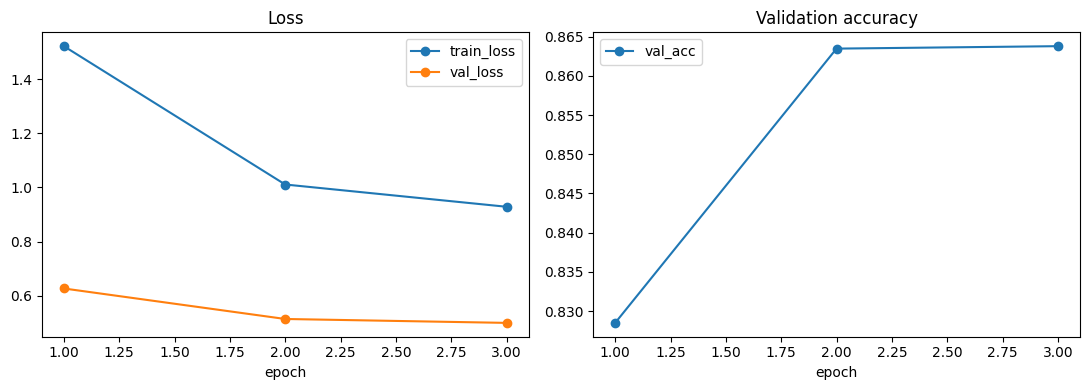

Best val acc: 0.8637925386428833


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
hist.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", ax=ax[0], title="Loss")
hist.plot(x="epoch", y="val_acc", marker="o", ax=ax[1], title="Validation accuracy")
plt.tight_layout(); plt.show(); print("Best val acc:", hist.val_acc.max())

8. **Interpretasi hasil training**

- **Konvergensi:** akurasi validasi naik tajam dari epoch 1 ke 2 (82,85% ke 86,35%), lalu hampir datar di epoch 3 (86,38%). Penurunan learning rate di akhir OneCycle membuat peningkatan mengecil, sehingga menambah epoch dengan konfigurasi sama kemungkinan hanya memberi sedikit tambahan.
- **Tidak ada tanda overfitting:** val loss terus turun (0,63 ke 0,50). Train loss lebih tinggi dari val loss karena dihitung selama training dengan label smoothing dan augmentasi, serta dirata-rata saat bobot masih berubah.
- **Efisiensi:** ~14 menit untuk 3 epoch di GPU berkat cache gambar.
- **Langkah lanjutan yang mungkin:** resolusi input lebih tinggi, augmentasi lebih beragam, ensemble beberapa model, atau tambahan fitur teks (OCR). Per-kelas dianalisis di notebook 03.